<a href="https://colab.research.google.com/github/waabbey/COS-202/blob/main/student_performance_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [ ]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nData types count:")
print(df.dtypes.value_counts())


Missing values per column:
Series([], dtype: int64)

Data types count:
object    17
int64     16
Name: count, dtype: int64


In [ ]:
key_cols = ["studytime", "failures", "absences", "G1", "G2", "G3"]
df[key_cols].describe()

,studytime,failures,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,2.035443,0.334177,5.708861,10.908861,10.713924,10.415190
std,0.839240,0.743651,8.003096,3.319195,3.761505,4.581443
min,1.000000,0.000000,0.000000,3.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,8.000000,9.000000,8.000000
50%,2.000000,0.000000,4.000000,11.000000,11.000000,11.000000
75%,2.000000,0.000000,8.000000,13.000000,13.000000,14.000000
max,4.000000,3.000000,75.000000,19.000000,19.000000,20.000000


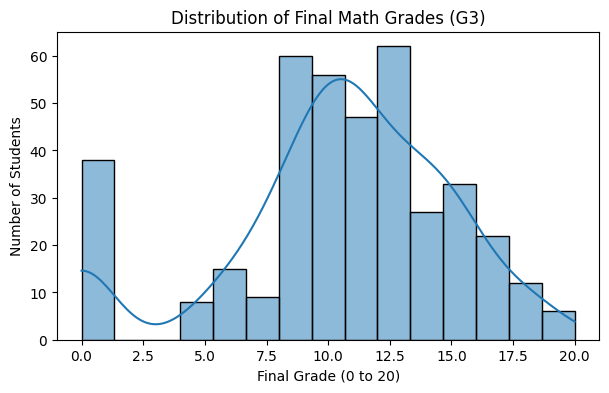

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.histplot(df["G3"], bins=15, kde=True)
plt.title("Distribution of Final Math Grades (G3)")
plt.xlabel("Final Grade (0 to 20)")
plt.ylabel("Number of Students")
plt.show()

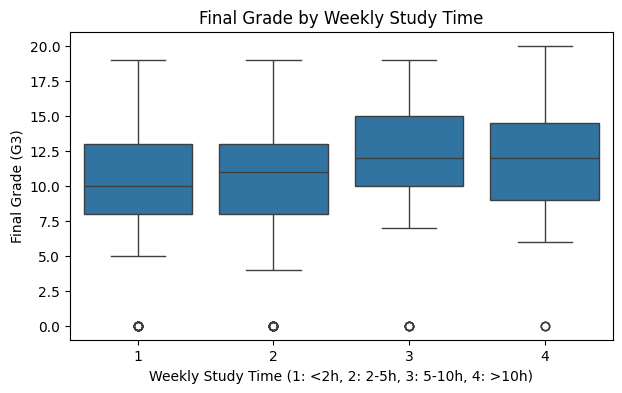

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="studytime", y="G3", data=df)
plt.title("Final Grade by Weekly Study Time")
plt.xlabel("Weekly Study Time (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h)")
plt.ylabel("Final Grade (G3)")
plt.show()

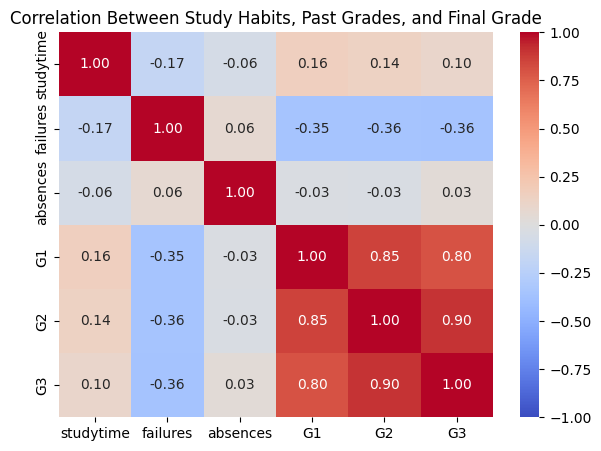

In [ ]:
numeric_cols = ["studytime", "failures", "absences", "G1", "G2", "G3"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Between Study Habits, Past Grades, and Final Grade")
plt.show()

In [ ]:

df["internet_num"] = df["internet"].map({"yes": 1, "no": 0})
df["activities_num"] = df["activities"].map({"yes": 1, "no": 0})

df[["internet", "internet_num", "activities", "activities_num"]].head()

,internet,internet_num,activities,activities_num
0,no,0,no,0
1,yes,1,no,0
2,yes,1,no,0
3,yes,1,yes,1
4,no,0,no,0


In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

features = ["studytime", "failures", "absences", "G1", "G2", "internet_num", "activities_num"]
X = df[features]
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"Average grade error (MAE): {mae:.2f} points (out of 20)")
print(f"R² score: {r2:.2f}")

Average grade error (MAE): 1.37 points (out of 20)
R² score: 0.77


In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("student-mat.csv", sep=";")
df["internet_num"] = df["internet"].map({"yes": 1, "no": 0})
df["activities_num"] = df["activities"].map({"yes": 1, "no": 0})

features = ["studytime", "failures", "absences", "G1", "G2", "internet_num", "activities_num"]
X = df[features]
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"Average grade error (MAE): {mae:.2f} points (out of 20)")
print(f"R² score: {r2:.2f}")

Average grade error (MAE): 1.37 points (out of 20)
R² score: 0.77


In [ ]:
coef_df = pd.DataFrame({
    "feature": features,
    "coefficient": model.coef_
}).sort_values(by="coefficient", ascending=False)

print(coef_df.to_string(index=False))
print(f"\nIntercept (starting baseline): {model.intercept_:.2f}")

       feature  coefficient
            G2     0.983612
            G1     0.141527
      absences     0.039891
     studytime    -0.040320
  internet_num    -0.132849
activities_num    -0.487822
      failures    -0.488320

Intercept (starting baseline): -1.33


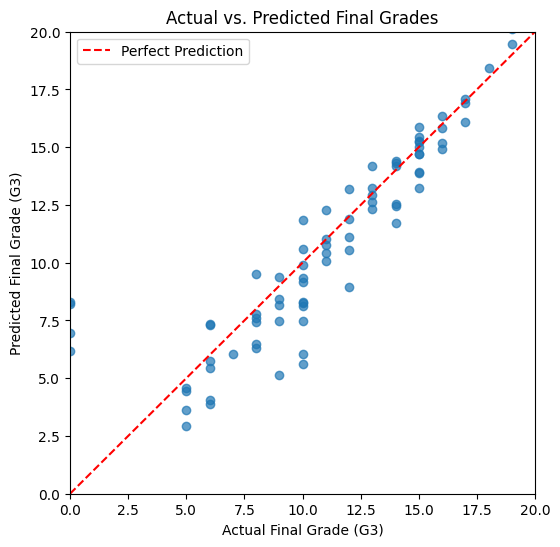

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.7)
plt.plot([0, 20], [0, 20], "--", color="red", label="Perfect Prediction")
plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade (G3)")
plt.title("Actual vs. Predicted Final Grades")
plt.legend()
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.show()

In [ ]:
habit_features = ["studytime", "failures", "absences", "internet_num", "activities_num"]
X_hab = df[habit_features]

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_hab, y, test_size=0.2, random_state=42
)

model_hab = LinearRegression()
model_hab.fit(X_train_h, y_train_h)

pred_hab = model_hab.predict(X_test_h)
mae_hab = mean_absolute_error(y_test_h, pred_hab)
r2_hab = r2_score(y_test_h, pred_hab)

print(f"Habits-only MAE: {mae_hab:.2f} (vs. 1.37 with G1 & G2)")
print(f"Habits-only R²:  {r2_hab:.2f} (vs. 0.77 with G1 & G2)")

Habits-only MAE: 3.67 (vs. 1.37 with G1 & G2)
Habits-only R²:  -0.01 (vs. 0.77 with G1 & G2)


In [ ]:
expanded_features = [
    "studytime",
    "failures",
    "absences",
    "internet_num",
    "activities_num",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health",
]

X_exp = df[expanded_features]

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_exp, y, test_size=0.2, random_state=42
)

model_exp = LinearRegression()
model_exp.fit(X_train_e, y_train_e)

pred_exp = model_exp.predict(X_test_e)
mae_exp = mean_absolute_error(y_test_e, pred_exp)
r2_exp = r2_score(y_test_e, pred_exp)

print(f"Expanded habits MAE: {mae_exp:.2f} (previous habits-only: 3.67)")
print(f"Expanded habits R²:  {r2_exp:.2f} (previous habits-only: -0.01)")

Expanded habits MAE: 3.59 (previous habits-only: 3.67)
Expanded habits R²:  0.04 (previous habits-only: -0.01)
